# Product Clustering , Approach 2: TF-IDF Vectors + BFR

**Feature:** `vector_tfidf` (1,000-dim TF-IDF, Task 2 pipeline)
**Algorithm:** BFR (Bradley-Fayyad-Reina, 1998) — chunk-based, memory-bounded
**Scale:** Full 5,737,625 products — no sampling required

| Parameter | Value |
|---|---|
| PCA sample | 50,000 products |
| PCA dims | 1,000 TO 50 |
| Batch size | 10,000 products |
| Mahalanobis threshold | 3.0 |
| Random seed | 42 |
| k (clusters) | Set in Section 5 after elbow analysis |


## 1. Environment Setup

Windows Hadoop/Spark configuration via `winutils.exe`. Skipped on macOS/Linux.


In [1]:
import os, sys

if sys.platform == 'win32':
    import urllib.request, pathlib
    os.environ['HADOOP_HOME']           = 'C:/hadoop'
    os.environ['PYSPARK_PYTHON']        = sys.executable
    os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
    hadoop_bin    = pathlib.Path('C:/hadoop/bin')
    hadoop_bin.mkdir(parents=True, exist_ok=True)
    winutils_path = hadoop_bin / 'winutils.exe'
    if not winutils_path.exists():
        url = 'https://github.com/cdarlint/winutils/raw/master/hadoop-3.3.5/bin/winutils.exe'
        urllib.request.urlretrieve(url, str(winutils_path))
        print('Downloaded winutils.exe.')
    else:
        print('winutils.exe already present.')
else:
    print(f'Platform: {sys.platform} — winutils not needed.')


winutils.exe already present.


## 2. Imports & Configuration



In [2]:
import sys, os, ast, time
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import euclidean_distances

from common.const import SCHEMA
from common.helper import clickhouse_extract_data_as_df

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

# Configuration 
PCA_SAMPLE_SIZE  = 50_000   # products used to fit PCA
PCA_COMPONENTS   = 50       # target dimensions after PCA
BATCH_SIZE       = 10_000   # products per ClickHouse chunk
MAHAL_THRESHOLD  = 3.0      # Mahalanobis threshold for DS assignment 
MIN_CS_SIZE      = 5        # min points to form a Compressed Set mini-cluster
RANDOM_SEED      = 42       # fixed seed for reproducibility

# Elbow analysis
K_RANGE      = range(2, 17)
ELBOW_SAMPLE = 20_000
SILHOUETTE_N = 5_000


print('Imports OK')
print(f'PCA: {PCA_SAMPLE_SIZE:,} sample to {PCA_COMPONENTS} dims')
print(f'BFR: batch={BATCH_SIZE:,} | mahal={MAHAL_THRESHOLD} | seed={RANDOM_SEED}')


Imports OK
PCA: 50,000 sample to 50 dims
BFR: batch=10,000 | mahal=3.0 | seed=42


## 3a. Phase 1 : PCA Sample

50,000 products sampled using rowNumberInAllBlocks() % 114 = 0
- deterministic,no sorting, evenly spread.
- Fitted PCA object is reused for all batches in Phase 2.


In [3]:
#  Random sample of 50,000 products for PCA fitting 
# Use modulo on rowNumberInAllBlocks() for a deterministic, evenly-spaced sample.
# For 50,000 from 5.7M rows, take every ~114th row.

SAMPLE_EVERY_N = max(1, 5_737_625 // PCA_SAMPLE_SIZE)

pca_sample_query = f"""
SELECT
    parent_asin,
    vector_tfidf
FROM {SCHEMA}.featured_dense_vectors
WHERE length(vector_tfidf) > 0
  AND rowNumberInAllBlocks() % {SAMPLE_EVERY_N} = 0
LIMIT {PCA_SAMPLE_SIZE}
"""

print(f'Fetching ~{PCA_SAMPLE_SIZE:,} products (every {SAMPLE_EVERY_N}th row)')
start      = time.time()
pca_sample = clickhouse_extract_data_as_df(pca_sample_query)
elapsed    = time.time() - start

# Fix column names
pca_sample.columns = [str(c).strip() for c in pca_sample.columns]
pca_sample = pca_sample.head(PCA_SAMPLE_SIZE).reset_index(drop=True)

print(f'Fetched   : {len(pca_sample):,} rows in {elapsed:.1f}s')
print(f'Columns   : {list(pca_sample.columns)}')
print(pca_sample.head(3))


Fetching ~50,000 products (every 114th row)
Fetched   : 50,000 rows in 47.6s
Columns   : ['parent_asin', 'vector_tfidf']
  parent_asin                                       vector_tfidf
0  0000191639  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
1  0545498562  [0.0, 0.0, 0.0, 0.0, 0.04564921, 0.0, 0.070735...
2  064685500X  [0.0, 0.0, 0.0, 0.1738916, 0.0, 0.0, 0.0, 0.0,...


### 3b. Parse Sample Vectors

Parse vector_tfidf strings to float32 numpy arrays and then stack into X_sample (50000, 1000).


In [4]:

def parse_vector(v):
    """Convert ClickHouse Array(Float32) to flat numpy float32 array."""
    if isinstance(v, (list, np.ndarray)):
        return np.array(v, dtype=np.float32)
    if isinstance(v, str):
        return np.array(ast.literal_eval(v), dtype=np.float32)
    return None

pca_sample['parsed'] = pca_sample['vector_tfidf'].apply(parse_vector)
pca_sample = pca_sample[pca_sample['parsed'].notna()].reset_index(drop=True)

X_sample = np.vstack(pca_sample['parsed'].values).astype(np.float32)

print(f'PCA sample matrix shape : {X_sample.shape}')
print(f'dtype                   : {X_sample.dtype}')
print(f'RAM estimate            : {X_sample.nbytes / 1e6:.1f} MB')
print(f'Non-zero fraction       : {(X_sample != 0).mean():.2%}')


PCA sample matrix shape : (50000, 1000)
dtype                   : float32
RAM estimate            : 200.0 MB
Non-zero fraction       : 4.70%


## 4. Phase 1b : Fit PCA

PCA reduces 1,000-dim TF-IDF to 50 dense dims.


In [5]:
print(f'Fitting PCA: {X_sample.shape[1]} to {PCA_COMPONENTS} dims on {len(X_sample):,} samples')
start = time.time()

pca = PCA(n_components=PCA_COMPONENTS, random_state=RANDOM_SEED)
X_sample_reduced = pca.fit_transform(X_sample)

elapsed = time.time() - start
print(f'PCA fitted in           : {elapsed:.1f}s')
print(f'Reduced shape           : {X_sample_reduced.shape}')
print(f'Variance explained      : {pca.explained_variance_ratio_.sum():.2%}')
print(f'Top 10 component var     : {pca.explained_variance_ratio_[:10].round(4)}')
print(f'\nPCA is ready ')

Fitting PCA: 1000 to 50 dims on 50,000 samples
PCA fitted in           : 0.6s
Reduced shape           : (50000, 50)
Variance explained      : 45.19%
Top 10 component var     : [0.0753 0.0279 0.021  0.0193 0.0171 0.0151 0.0127 0.0119 0.0117 0.0108]

PCA is ready 


## 5. Optimal k: Elbow + Silhouette

- k tested from 2–16 on 20,000 PCA-reduced products. 
- Two metrics: WCSS (elbow) + Silhouette (cosine).

**Note:** Low silhouette is normal for sparse TF-IDF (Steinbach et al., 2000)

In [6]:
# Independent RNG — not affected by any other cell in the notebook
rng  = np.random.default_rng(42)
rng2 = np.random.default_rng(43)

# Sample from the PCA-reduced sample for elbow analysis
n_elbow    = min(ELBOW_SAMPLE, len(X_sample_reduced))
s_idx      = rng.choice(len(X_sample_reduced), n_elbow, replace=False)
sample_emb = X_sample_reduced[s_idx]

# Separate seed for silhouette sample
sil_n   = min(SILHOUETTE_N, n_elbow)
sil_idx = rng2.choice(n_elbow, sil_n, replace=False)

k_values, wcss_values, sil_values = [], [], []
print(f'Testing k ∈ {{2..16}} on {n_elbow:,} PCA-reduced products')
print()

for k in K_RANGE:
    km     = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10, max_iter=300)
    labels = km.fit_predict(sample_emb)
    wcss   = km.inertia_
    sil    = silhouette_score(sample_emb[sil_idx], labels[sil_idx], metric='cosine')
    k_values.append(k); wcss_values.append(wcss); sil_values.append(sil)
    print(f'  k={k:2d} : WCSS={wcss:>10.2f}  Silhouette={sil:.4f}')

print('\nReview the plot in Section and then set N_CLUSTERS manually.')


Testing k ∈ {2..16} on 20,000 PCA-reduced products

  k= 2 : WCSS=   7008.70  Silhouette=0.2478
  k= 3 : WCSS=   6608.60  Silhouette=0.1953
  k= 4 : WCSS=   6305.77  Silhouette=0.1997
  k= 5 : WCSS=   6077.05  Silhouette=0.1595
  k= 6 : WCSS=   5874.03  Silhouette=0.1590
  k= 7 : WCSS=   5690.31  Silhouette=0.1643
  k= 8 : WCSS=   5560.26  Silhouette=0.1850
  k= 9 : WCSS=   5438.30  Silhouette=0.1855
  k=10 : WCSS=   5253.36  Silhouette=0.2030
  k=11 : WCSS=   5132.12  Silhouette=0.1957
  k=12 : WCSS=   5029.85  Silhouette=0.2007
  k=13 : WCSS=   4896.42  Silhouette=0.2151
  k=14 : WCSS=   4829.07  Silhouette=0.1999
  k=15 : WCSS=   4749.51  Silhouette=0.2130
  k=16 : WCSS=   4629.33  Silhouette=0.2140

Review the plot in Section and then set N_CLUSTERS manually.


### 5a. Elbow & Silhouette Plot


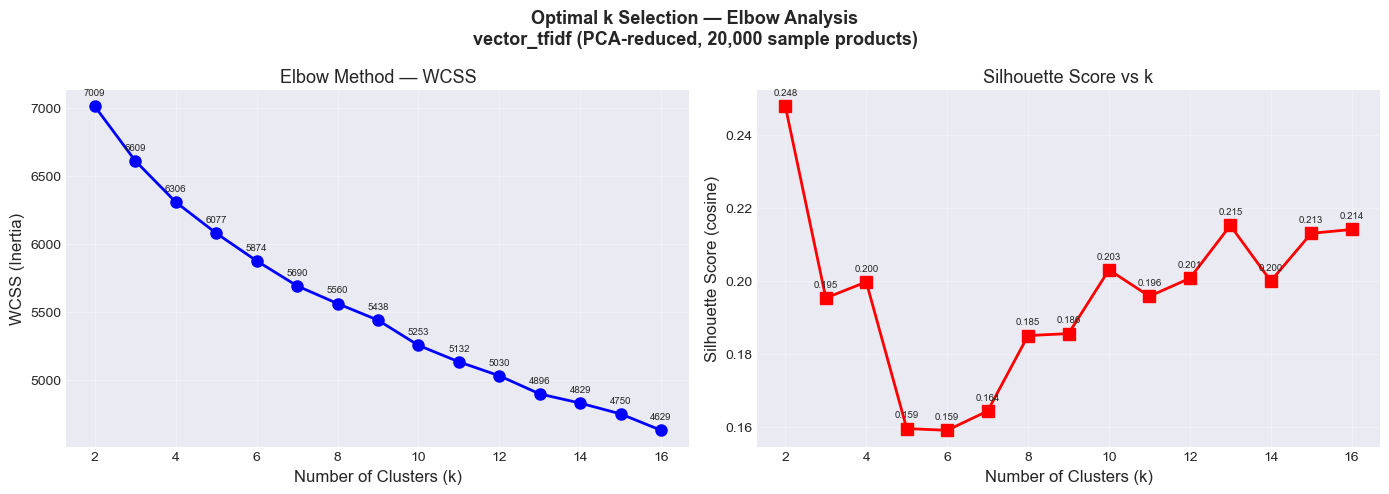

Saved: elbow_bfr_tfidf.png


In [7]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    'Optimal k Selection — Elbow Analysis\n'
    f'vector_tfidf (PCA-reduced, {n_elbow:,} sample products)',
    fontsize=13, fontweight='bold'
)

axes[0].plot(k_values, wcss_values, 'bo-', lw=2, ms=8)
axes[0].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[0].set_ylabel('WCSS (Inertia)', fontsize=12)
axes[0].set_title('Elbow Method — WCSS', fontsize=13)
axes[0].grid(alpha=0.3)
for x, y in zip(k_values, wcss_values):
    axes[0].annotate(f'{y:.0f}', (x, y), textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=7)

axes[1].plot(k_values, sil_values, 'rs-', lw=2, ms=8)
axes[1].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[1].set_ylabel('Silhouette Score (cosine)', fontsize=12)
axes[1].set_title('Silhouette Score vs k', fontsize=13)
axes[1].grid(alpha=0.3)
for x, y in zip(k_values, sil_values):
    axes[1].annotate(f'{y:.3f}', (x, y), textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=7)

plt.tight_layout()
plt.savefig('elbow_bfr_tfidf.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: elbow_bfr_tfidf.png')


### 5b. k Selection 

k=2 rejected as is too small and not detailed enough for entire Amazon category.
k=10 is chosen as the silhouette score stops improving much after this point and WCSS improvement become smaller and smaller.

In [8]:
#  Manual k selection
N_CLUSTERS = 10
print(f'N_CLUSTERS(k) = {N_CLUSTERS}')

N_CLUSTERS(k) = 10


## 6a. BFR Algorithm - Implementation

In [9]:
class BFRCluster:
    """
    One BFR Discard Set (DS) cluster summary.

    Stores ONLY (N, SUM, SUMSQ) per dimension not raw points.
    All statistics (centroid, variance, Mahalanobis) are computed on demand.
    """

    def __init__(self, cluster_id: int, initial_points: np.ndarray):
        self.id    = cluster_id
        self.n     = len(initial_points)
        self.sum_  = initial_points.sum(axis=0)            
        self.sumsq = (initial_points ** 2).sum(axis=0)     

    @property
    def centroid(self) -> np.ndarray:
        """Mean vector of all assigned points."""
        return self.sum_ / self.n

    @property
    def variance(self) -> np.ndarray:
        """Per-dimension variance. Clipped to avoid zero-division."""
        var = self.sumsq / self.n - (self.sum_ / self.n) ** 2
        return np.clip(var, 1e-8, None)

    def mahalanobis(self, points: np.ndarray) -> np.ndarray:
        """
        Mahalanobis distance from each point to this cluster centroid.
        Parameters:  points shape (n, d)
        Returns:     distances shape (n,)
        """
        diff = points - self.centroid           # (n, d)
        return np.sqrt((diff ** 2 / self.variance).sum(axis=1))

    def absorb(self, points: np.ndarray):
        """Update summary statistics with new points. Raw points are discarded."""
        self.n     += len(points)
        self.sum_  += points.sum(axis=0)
        self.sumsq += (points ** 2).sum(axis=0)

    def __repr__(self):
        return (f'BFRCluster(id={self.id}, n={self.n:,}, '
                f'centroid={self.centroid[:3].round(3)})')


print('BFRCluster defined.')


BFRCluster defined.


### 6b. BFR Streaming manager


In [10]:
class BFR:
    """
    Bradley-Fayyad-Reina (BFR) clustering — streaming / chunk-based.
    Parameters : k ,mahal_threshold ,min_cs_size,random_state 
    
    """

    def __init__(self, k, mahal_threshold=3.0, min_cs_size=5, random_state=42):
        self.k               = k
        self.mahal_threshold = mahal_threshold
        self.min_cs_size     = min_cs_size
        self.random_state    = random_state
        self.clusters_       = []   # DS clusters (BFRCluster objects)
        self._rs             = None # Retained Set (raw vectors)

    
    def initialise(self, first_batch: np.ndarray):
        """
        Fit initial DS clusters using K-Means++ on the first batch.
        """
        km = KMeans(
            n_clusters=self.k, init='k-means++',
            n_init=10, random_state=self.random_state, max_iter=300
        )
        init_labels = km.fit_predict(first_batch)

        self.clusters_ = []
        for cid in range(self.k):
            pts = first_batch[init_labels == cid]
            if len(pts) == 0:
                pts = km.cluster_centers_[cid:cid+1]  # use centroid
            self.clusters_.append(BFRCluster(cid, pts))

        self._rs = np.empty((0, first_batch.shape[1]), dtype=np.float32)
        print(f'  Initialised {self.k} DS clusters from {len(first_batch):,} points.')

    # DS assignment 
    def _assign_to_ds(self, points: np.ndarray):
        """
        Assign points to DS clusters by Mahalanobis distance.
        Returns (labels array, unassigned boolean mask).
        labels[i] = cluster_id if assigned, -1 if not.
        """
        n      = len(points)
        labels = np.full(n, -1, dtype=np.int32)

        # Distance matrix
        dist_matrix = np.column_stack([
            c.mahalanobis(points) for c in self.clusters_
        ])

        nearest_cluster = dist_matrix.argmin(axis=1)
        nearest_dist    = dist_matrix.min(axis=1)

        assigned              = nearest_dist < self.mahal_threshold
        labels[assigned]      = nearest_cluster[assigned]
        return labels, ~assigned

    # CS handling 
    def _process_rs(self, rs: np.ndarray) -> np.ndarray:
        """
        Run mini K-Means on RS to discover CS mini-clusters.
        Mature CS clusters (size >= min_cs_size) are merged into nearest DS.
        Returns updated RS (true outliers that didn't cluster).
        """
        if len(rs) < self.min_cs_size * 2:
            return rs

        n_cs = max(2, min(int(np.sqrt(len(rs))), len(rs) // self.min_cs_size))
        km   = KMeans(n_clusters=n_cs, n_init=3,
                      random_state=self.random_state, max_iter=50)
        cs_labels = km.fit_predict(rs)

        new_rs = []
        for cs_id in range(n_cs):
            cs_pts = rs[cs_labels == cs_id]
            if len(cs_pts) >= self.min_cs_size:
                # Merge CS into nearest DS centroid
                centroid    = cs_pts.mean(axis=0, keepdims=True)
                dist_to_ds  = np.array([c.mahalanobis(centroid)[0]
                                        for c in self.clusters_])
                self.clusters_[dist_to_ds.argmin()].absorb(cs_pts)
            else:
                new_rs.extend(cs_pts.tolist())

        return (np.array(new_rs, dtype=np.float32)
                if new_rs else np.empty((0, rs.shape[1]), dtype=np.float32))

    #  Process one batch 
    def process_batch(self, batch: np.ndarray) -> np.ndarray:
        """
        Process one batch of PCA-reduced vectors.

        - Assign points to DS via Mahalanobis distance
        - Update DS summaries (raw points discarded)
        - Add unassigned to RS
        - Process RS to find CS mini-clusters
        - Return labels for this batch (-1 = unassigned, resolved at end)

        Parameters:  batch shape (n, d)
        Returns:     labels shape (n,)  : -1 for unresolved points
        """
        labels, unassigned = self._assign_to_ds(batch)

        # Update DS with assigned points (raw vectors discarded after this)
        for cid in range(self.k):
            pts = batch[labels == cid]
            if len(pts) > 0:
                self.clusters_[cid].absorb(pts)

        # Accumulate unassigned into RS and process
        if unassigned.any():
            self._rs = np.vstack([self._rs, batch[unassigned]])
            self._rs = self._process_rs(self._rs)

        return labels

    def resolve_remaining(self, batch: np.ndarray) -> np.ndarray:
        """
        Final assignment: assign any remaining RS / unresolved points to
        nearest cluster centroid by Euclidean distance.
        Called once after all batches are processed.
        """
        centroids = self.cluster_centers_()
        dists     = np.linalg.norm(
            batch[:, None, :] - centroids[None, :, :], axis=2
        )
        return dists.argmin(axis=1)

    def cluster_centers_(self) -> np.ndarray:
        """Return centroid of each DS cluster."""
        return np.vstack([c.centroid for c in self.clusters_])

    def cluster_sizes_(self) -> dict:
        """Return {cluster_id: n_points} for each DS cluster."""
        return {c.id: c.n for c in self.clusters_}


print('BFR class defined.')


BFR class defined.


## 7. Phase 2 : Stream Full Dataset

### 7a. Reset & Count

Clears all_asins / all_labels accumulators then queries exact row count.


In [11]:

#  Reset accumulators 
all_asins  = []
all_labels = []
print('Accumulators reset.')

#  Get total product count 
count_query = f"""
SELECT count() AS total
FROM {SCHEMA}.featured_dense_vectors
WHERE length(vector_tfidf) > 0
"""

total_df   = clickhouse_extract_data_as_df(count_query)
TOTAL_ROWS = int(total_df['total'].iloc[0])
n_batches  = int(np.ceil(TOTAL_ROWS / BATCH_SIZE))

print(f'Total products  : {TOTAL_ROWS:,}')
print(f'Batch size      : {BATCH_SIZE:,}')
print(f'Total batches   : {n_batches:,}')
print(f'Est. time       : {n_batches * 2 / 60:.0f}–{n_batches * 3 / 60:.0f} minutes')


Accumulators reset.
Total products  : 5,737,625
Batch size      : 10,000
Total batches   : 574
Est. time       : 19–29 minutes


### 7b. Initialise BFR from First Batch

Fetches first BATCH_SIZE=10,000 products with LIMIT (no ORDER BY).
K-Means++ on this batch seeds the k=10 DS cluster centroids.


In [12]:
#  Initialise BFR from first batch 
# Fetch first 100,000 ASINs directly — no rowNumberInAllBlocks() needed
# all_asins and all_labels already reset in Section 7a

print(f'Initialising BFR (k={N_CLUSTERS}) from first batch...')

first_batch_query = f"""
SELECT parent_asin, vector_tfidf
FROM {SCHEMA}.featured_dense_vectors
WHERE length(vector_tfidf) > 0
LIMIT {BATCH_SIZE}
"""

first_df           = clickhouse_extract_data_as_df(first_batch_query)
first_df.columns   = [str(c).strip() for c in first_df.columns]
first_df['parsed'] = first_df['vector_tfidf'].apply(parse_vector)
first_df           = first_df[first_df['parsed'].notna()].reset_index(drop=True)

first_batch = pca.transform(
    np.vstack(first_df['parsed'].values).astype(np.float32)
)

bfr = BFR(
    k=N_CLUSTERS,
    mahal_threshold=MAHAL_THRESHOLD,
    min_cs_size=MIN_CS_SIZE,
    random_state=RANDOM_SEED
)
bfr.initialise(first_batch)

# Assign first batch labels
first_labels, _  = bfr._assign_to_ds(first_batch)
unresolved_mask  = first_labels == -1
if unresolved_mask.any():
    first_labels[unresolved_mask] = bfr.resolve_remaining(
        first_batch[unresolved_mask]
    )

all_asins  = list(first_df['parent_asin'])
all_labels = list(first_labels)

print(f'First batch     : {len(all_asins):,} products')
print(f'DS cluster sizes: {bfr.cluster_sizes_()}')

Initialising BFR (k=10) from first batch...
  Initialised 10 DS clusters from 10,000 points.
First batch     : 10,000 products
DS cluster sizes: {0: 3885, 1: 731, 2: 383, 3: 1111, 4: 305, 5: 2130, 6: 227, 7: 261, 8: 565, 9: 402}


### 7c. Stream All Remaining Batches

**Two-step IN() approach:**
1. Fetch all 5.7M parent_asin values (text only)
2. Split into chunks of 10,000, fetch vectors with WHERE parent_asin IN (...)

Progress printed every 50 chunks with **Elapsed / ETA / Labelled / RS / Failed**.


In [13]:

# Stream full dataset through BFR 

print('Step 1: Fetching all parent_asins')
start = time.time()

all_asins_query = f"""
SELECT parent_asin
FROM {SCHEMA}.featured_dense_vectors
WHERE length(vector_tfidf) > 0
"""

all_asins_df = clickhouse_extract_data_as_df(all_asins_query)
all_asins_df.columns = [str(c).strip() for c in all_asins_df.columns]
all_asin_list = all_asins_df['parent_asin'].tolist()

# Remove first batch asins already processed
processed      = set(all_asins)
remaining_asins = [a for a in all_asin_list if a not in processed]

print(f'Total ASINs      : {len(all_asin_list):,}')
print(f'Already done     : {len(processed):,} (first batch)')
print(f'Remaining        : {len(remaining_asins):,}')
print(f'Fetched in       : {time.time()-start:.1f}s')

# Split remaining into chunks
chunks   = [remaining_asins[i:i+BATCH_SIZE]
            for i in range(0, len(remaining_asins), BATCH_SIZE)]
n_chunks = len(chunks)
print(f'Chunks to process: {n_chunks:,}')
print()
print('Step 2: Streaming chunks through BFR...')
print()

start  = time.time()
failed = 0

for batch_idx, chunk_asins in enumerate(chunks):
    asin_list_sql = ', '.join(f"'{a}'" for a in chunk_asins)

    batch_query = f"""
    SELECT parent_asin, vector_tfidf
    FROM {SCHEMA}.featured_dense_vectors
    WHERE parent_asin IN ({asin_list_sql})
      AND length(vector_tfidf) > 0
    """

    try:
        batch_df = clickhouse_extract_data_as_df(batch_query)
        if len(batch_df) == 0:
            continue

        batch_df.columns   = [str(c).strip() for c in batch_df.columns]
        batch_df['parsed'] = batch_df['vector_tfidf'].apply(parse_vector)
        batch_df = batch_df[batch_df['parsed'].notna()].reset_index(drop=True)

        if len(batch_df) == 0:
            continue

        # PCA transform , 1000-dim vectors discarded after this
        batch_reduced = pca.transform(
            np.vstack(batch_df['parsed'].values).astype(np.float32)
        )

        # BFR assign ,DS summaries updated, batch_reduced discarded
        batch_labels = bfr.process_batch(batch_reduced)

        # Resolve any unassigned RS outliers
        unresolved = batch_labels == -1
        if unresolved.any():
            batch_labels[unresolved] = bfr.resolve_remaining(
                batch_reduced[unresolved]
            )

        all_asins.extend(batch_df['parent_asin'].tolist())
        all_labels.extend(batch_labels.tolist())

    except Exception as e:
        failed += 1
        print(f'  WARNING: chunk {batch_idx} failed — {e}')
        continue

    # Progress every 50 chunks with ETA
    if batch_idx % 50 == 0 or batch_idx == n_chunks - 1:
        elapsed = time.time() - start
        pct     = (batch_idx + 1) / n_chunks * 100
        eta     = (elapsed / (batch_idx + 1)) * (n_chunks - batch_idx - 1)
        print(f'  Chunk {batch_idx+1:4d}/{n_chunks} ({pct:5.1f}%) | '
              f'Elapsed: {elapsed/60:.1f}m | '
              f'ETA: {eta/60:.1f}m | '
              f'Labelled: {len(all_labels):,} | '
              f'RS: {len(bfr._rs):,} | '
              f'Failed: {failed}')

total_time = time.time() - start
print(f'\nBFR complete in {total_time/60:.1f} minutes')
print(f'Total products labelled : {len(all_labels):,}')
print(f'Failed chunks           : {failed}')
print('\nFinal DS cluster sizes:')
for cid, n in sorted(bfr.cluster_sizes_().items()):
    print(f'  Cluster {cid}: {n:,} ({n/len(all_labels)*100:.1f}%)')

Step 1: Fetching all parent_asins
Total ASINs      : 5,737,625
Already done     : 10,000 (first batch)
Remaining        : 5,727,625
Fetched in       : 9.8s
Chunks to process: 573

Step 2: Streaming chunks through BFR...

  Chunk    1/573 (  0.2%) | Elapsed: 0.1m | ETA: 29.0m | Labelled: 20,000 | RS: 3 | Failed: 0
  Chunk   51/573 (  8.9%) | Elapsed: 2.6m | ETA: 26.6m | Labelled: 526,412 | RS: 0 | Failed: 0
  Chunk  101/573 ( 17.6%) | Elapsed: 5.1m | ETA: 23.7m | Labelled: 1,026,412 | RS: 0 | Failed: 0
  Chunk  151/573 ( 26.4%) | Elapsed: 7.6m | ETA: 21.1m | Labelled: 1,526,412 | RS: 0 | Failed: 0
  Chunk  201/573 ( 35.1%) | Elapsed: 10.0m | ETA: 18.6m | Labelled: 2,032,824 | RS: 0 | Failed: 0
  Chunk  251/573 ( 43.8%) | Elapsed: 12.5m | ETA: 16.1m | Labelled: 2,532,824 | RS: 0 | Failed: 0
  Chunk  301/573 ( 52.5%) | Elapsed: 15.0m | ETA: 13.6m | Labelled: 3,032,824 | RS: 0 | Failed: 0
  Chunk  351/573 ( 61.3%) | Elapsed: 17.6m | ETA: 11.1m | Labelled: 3,536,370 | RS: 0 | Failed: 0
  Ch

### 7d. Build Results DataFrame

Combine all (parent_asin, cluster_label) pairs. Deduplicate and reset index.


In [14]:
#  Build results DataFrame 
results_df = pd.DataFrame({
    'parent_asin': all_asins,
    'bfr_cluster': all_labels
}).drop_duplicates(subset='parent_asin').reset_index(drop=True)

print(f'Results shape : {results_df.shape}')
print('Cluster distribution:')
print(results_df['bfr_cluster'].value_counts().sort_index())


Results shape : (5728247, 2)
Cluster distribution:
bfr_cluster
0     719003
1    1859547
2     238040
3     402380
4     296152
5     341667
6     116252
7     135109
8    1423936
9     196161
Name: count, dtype: int64


In [15]:
# Stream full dataset through BFR 

print('Step 1: Fetching all parent_asins')
start = time.time()

all_asins_query = f"""
SELECT parent_asin
FROM {SCHEMA}.featured_dense_vectors
WHERE length(vector_tfidf) > 0
"""

all_asins_df = clickhouse_extract_data_as_df(all_asins_query)
all_asins_df.columns = [str(c).strip() for c in all_asins_df.columns]
all_asin_list = all_asins_df['parent_asin'].tolist()

# Remove first batch asins already processed
processed      = set(all_asins)
remaining_asins = [a for a in all_asin_list if a not in processed]

print(f'Total ASINs      : {len(all_asin_list):,}')
print(f'Already done     : {len(processed):,} (first batch)')
print(f'Remaining        : {len(remaining_asins):,}')
print(f'Fetched in       : {time.time()-start:.1f}s')

# Split remaining into chunks
chunks   = [remaining_asins[i:i+BATCH_SIZE]
            for i in range(0, len(remaining_asins), BATCH_SIZE)]
n_chunks = len(chunks)
print(f'Chunks to process: {n_chunks:,}')
print()
print('Step 2: Streaming chunks through BFR...')
print()

start  = time.time()
failed = 0

for batch_idx, chunk_asins in enumerate(chunks):
    asin_list_sql = ', '.join(f"'{a}'" for a in chunk_asins)

    batch_query = f"""
    SELECT parent_asin, vector_tfidf
    FROM {SCHEMA}.featured_dense_vectors
    WHERE parent_asin IN ({asin_list_sql})
      AND length(vector_tfidf) > 0
    """

    try:
        batch_df = clickhouse_extract_data_as_df(batch_query)
        if len(batch_df) == 0:
            continue

        batch_df.columns   = [str(c).strip() for c in batch_df.columns]
        batch_df['parsed'] = batch_df['vector_tfidf'].apply(parse_vector)
        batch_df = batch_df[batch_df['parsed'].notna()].reset_index(drop=True)

        if len(batch_df) == 0:
            continue

        # PCA transform , 1000-dim vectors discarded after this
        batch_reduced = pca.transform(
            np.vstack(batch_df['parsed'].values).astype(np.float32)
        )

        # BFR assign ,DS summaries updated, batch_reduced discarded
        batch_labels = bfr.process_batch(batch_reduced)

        # Resolve any unassigned RS outliers
        unresolved = batch_labels == -1
        if unresolved.any():
            batch_labels[unresolved] = bfr.resolve_remaining(
                batch_reduced[unresolved]
            )

        all_asins.extend(batch_df['parent_asin'].tolist())
        all_labels.extend(batch_labels.tolist())

    except Exception as e:
        failed += 1
        print(f'  WARNING: chunk {batch_idx} failed — {e}')
        continue

    # Progress every 50 chunks with ETA
    if batch_idx % 50 == 0 or batch_idx == n_chunks - 1:
        elapsed = time.time() - start
        pct     = (batch_idx + 1) / n_chunks * 100
        eta     = (elapsed / (batch_idx + 1)) * (n_chunks - batch_idx - 1)
        print(f'  Chunk {batch_idx+1:4d}/{n_chunks} ({pct:5.1f}%) | '
              f'Elapsed: {elapsed/60:.1f}m | '
              f'ETA: {eta/60:.1f}m | '
              f'Labelled: {len(all_labels):,} | '
              f'RS: {len(bfr._rs):,} | '
              f'Failed: {failed}')

total_time = time.time() - start
print(f'\nBFR complete in {total_time/60:.1f} minutes')
print(f'Total products labelled : {len(all_labels):,}')
print(f'Failed chunks           : {failed}')
print('\nFinal DS cluster sizes:')
for cid, n in sorted(bfr.cluster_sizes_().items()):
    print(f'  Cluster {cid}: {n:,} ({n/len(all_labels)*100:.1f}%)')

Step 1: Fetching all parent_asins
Total ASINs      : 5,737,625
Already done     : 5,728,247 (first batch)
Remaining        : 0
Fetched in       : 12.4s
Chunks to process: 0

Step 2: Streaming chunks through BFR...


BFR complete in 0.0 minutes
Total products labelled : 5,756,381
Failed chunks           : 0

Final DS cluster sizes:
  Cluster 0: 210,428 (3.7%)
  Cluster 1: 2,883,353 (50.1%)
  Cluster 2: 191,441 (3.3%)
  Cluster 3: 177,653 (3.1%)
  Cluster 4: 182,460 (3.2%)
  Cluster 5: 287,787 (5.0%)
  Cluster 6: 85,525 (1.5%)
  Cluster 7: 121,631 (2.1%)
  Cluster 8: 1,477,317 (25.7%)
  Cluster 9: 138,786 (2.4%)


## 8. Evaluation — Silhouette & WCSS

Evaluated on 20,000-product sample .(O(n²) on full 5.7M is infeasible).
BFR centroids from `cluster_centers_()` are exact , computed from all 5.7M assigned points via `SUM/N`.

**Silhouette (cosine):** fit vs nearest other cluster. Range [−1,1], higher better.
**WCSS:** compactness using exact BFR centroids.


### 8a. Fetch Evaluation Sample Vectors

In [16]:
#  Sample 20,000 products for evaluation 
EVAL_SAMPLE = 20_000
eval_asins  = results_df['parent_asin'].sample(
    min(EVAL_SAMPLE, len(results_df)), random_state=RANDOM_SEED
).tolist()

asin_list_eval = ', '.join(f"'{a}'" for a in eval_asins)

eval_query = f"""
SELECT parent_asin, vector_tfidf
FROM {SCHEMA}.featured_dense_vectors
WHERE parent_asin IN ({asin_list_eval})
  AND length(vector_tfidf) > 0
"""

eval_df = clickhouse_extract_data_as_df(eval_query)
eval_df['parsed'] = eval_df['vector_tfidf'].apply(parse_vector)
eval_df = eval_df[eval_df['parsed'].notna()].reset_index(drop=True)

# PCA transform
X_eval = pca.transform(
    np.vstack(eval_df['parsed'].values).astype(np.float32)
)

# Merge cluster labels
eval_df = eval_df[['parent_asin']].merge(results_df, on='parent_asin', how='inner')
eval_labels = eval_df['bfr_cluster'].values

print(f'Evaluation sample : {len(eval_df):,} products')


Evaluation sample : 20,039 products


### 8b. Compute Silhouette Score & WCSS

Silhouette computed on the 20,000-product eval sample using cosine distance.
WCSS computed using BFR's exact centroids against the same eval sample.


In [17]:
# Silhouette Score 
silhouette = silhouette_score(X_eval, eval_labels, metric='cosine')

#  WCSS on sample 
centroids = bfr.cluster_centers_()
wcss = 0.0
for cid in range(N_CLUSTERS):
    pts = X_eval[eval_labels == cid]
    if len(pts) > 0:
        wcss += ((pts - centroids[cid]) ** 2).sum()

print('─' * 50)
print('EVALUATION RESULTS')
print('─' * 50)
print(f'Silhouette Score (cosine) : {silhouette:.4f}')
print(f'WCSS (sample)             : {wcss:.4f}')
print(f'k                         : {N_CLUSTERS}')
print(f'Total products clustered  : {len(results_df):,}')
print(f'Evaluation sample size    : {len(eval_df):,}')
print('─' * 50)


──────────────────────────────────────────────────
EVALUATION RESULTS
──────────────────────────────────────────────────
Silhouette Score (cosine) : 0.1130
WCSS (sample)             : 6103.0629
k                         : 10
Total products clustered  : 5,728,247
Evaluation sample size    : 20,039
──────────────────────────────────────────────────


## 9. Load Metadata for Profiling

Stratified sample of up to 3,000 products per cluster for profiling.
Full cluster sizes from the 5.7M run remain authoritative ( sample is for analysis only).


### 9a. Sample Metadata per Cluster

In [19]:
#  Stratified sample: up to 3,000 products per cluster for profiling 
PROFILE_SAMPLE = 3_000

sampled_rows = []
for cid in sorted(results_df['bfr_cluster'].unique()):
    cluster_asins = results_df[results_df['bfr_cluster'] == cid]
    sample        = cluster_asins.sample(
        min(PROFILE_SAMPLE, len(cluster_asins)), random_state=RANDOM_SEED
    )
    sampled_rows.append(sample)

profile_sample_df = pd.concat(sampled_rows).reset_index(drop=True)
print(f'Profile sample size : {len(profile_sample_df):,} products')
print(profile_sample_df['bfr_cluster'].value_counts().sort_index())

#  Fetch metadata for sampled ASINs 
profile_asins = ', '.join(f"'{a}'" for a in profile_sample_df['parent_asin'].tolist())

meta_query = f"""
SELECT
    parent_asin,
    title,
    main_category,
    product_category,
    CAST(price AS Nullable(Float64)) AS price,
    average_rating,
    rating_number
FROM {SCHEMA}.raw_products
WHERE parent_asin IN ({profile_asins})
  AND title IS NOT NULL
"""

meta_df     = clickhouse_extract_data_as_df(meta_query)
meta_df     = meta_df.drop_duplicates(subset='parent_asin').reset_index(drop=True)
products_df = profile_sample_df.merge(meta_df, on='parent_asin', how='left')

print(f'\nproducts_df shape   : {products_df.shape}')
print(f'Main categories     : {products_df["main_category"].nunique()}')


Profile sample size : 30,000 products
bfr_cluster
0    3000
1    3000
2    3000
3    3000
4    3000
5    3000
6    3000
7    3000
8    3000
9    3000
Name: count, dtype: int64

products_df shape   : (30000, 8)
Main categories     : 39


## 10. Cluster Profiling

### 10a. Print Cluster Statistics

In [20]:
# Full cluster sizes from the 5.7M run
full_sizes = results_df['bfr_cluster'].value_counts().sort_index()

print('=' * 65)
print('CLUSTER PROFILES — vector_tfidf + BFR (full 5.7M products)')
print('=' * 65)

for cid in sorted(products_df['bfr_cluster'].dropna().unique()):
    cd       = products_df[products_df['bfr_cluster'] == cid]
    sz_full  = full_sizes.get(cid, 0)
    sz_samp  = len(cd)
    pct_full = sz_full / len(results_df) * 100

    top_cats    = cd['main_category'].value_counts().head(3)
    avg_price   = cd['price'].dropna().mean()
    med_price   = cd['price'].dropna().median()
    avg_rating  = cd['average_rating'].mean()
    avg_reviews = cd['rating_number'].mean()

    print(f'\nCluster {int(cid)}')
    print(f'  Full dataset  : {sz_full:,} products ({pct_full:.1f}%)')
    print(f'  Profile sample: {sz_samp:,} products')
    print(f'  Top categories: {top_cats.to_dict()}')
    if pd.notna(avg_price):
        print(f'  Avg price     : ${avg_price:.2f}  Median: ${med_price:.2f}')
    else:
        print(f'  Avg price     : N/A')
    print(f'  Avg rating    : {avg_rating:.2f} / 5.0')
    print(f'  Avg reviews   : {avg_reviews:.0f}')
    print(f'  Sample titles :')
    for t in cd['title'].dropna().head(3):
        print(f'    - {str(t)[:80]}')


CLUSTER PROFILES — vector_tfidf + BFR (full 5.7M products)

Cluster 0
  Full dataset  : 719,003 products (12.6%)
  Profile sample: 3,000 products
  Top categories: {'Toys & Games': 2143, 'All Beauty': 146, 'Industrial & Scientific': 93}
  Avg price     : $42.31  Median: $19.99
  Avg rating    : 4.27 / 5.0
  Avg reviews   : 163
  Sample titles :
    - Old Fashion Original Red Heel Sock Monkey
    - View Master The Waltons 3D 3 Reel Packet
    - PolyHero Dice: Rogue: 7-Dice Set: Midnight Blue

Cluster 1
  Full dataset  : 1,859,547 products (32.5%)
  Profile sample: 3,000 products
  Top categories: {'Cell Phones & Accessories': 1475, 'All Electronics': 426, 'Computers': 280}
  Avg price     : $46.39  Median: $15.99
  Avg rating    : 4.01 / 5.0
  Avg reviews   : 166
  Sample titles :
    - High Capacity for JBL flip 4 Speakers Replacement Battery + Tool Shockproof Spon
    - HEALTHCARE SUPPLIER X Ray Sensor Sleeve (Size 2)
    - [Buy World] for Samsung Epic Touch 4g D710 Galaxy S2 (Sprint)

### 10b. Assign Descriptive Cluster Names

Replace each `[update after running]` with a short theme-based name.
Names are merged into both `products_df` (profile) and `results_df` (full 5.7M).


In [23]:
cluster_names = {
    0: 'Toys, Collectibles & Novelty Products',  # Toys, Beauty, Industrial
    1: 'Mobile & Consumer Electronics',           # Cell Phones, Electronics, Computers
    2: 'Computer Hardware & USB Accessories',     # Computers, Electronics, USB/Flash
    3: 'Arts, Crafts & Sewing Supplies',          # Arts & Crafts, Home, patches/stamps
    4: 'Phone Cases & Screen Protectors',         # Cell Phones — OtterBox, iPhone cases
    5: 'Baby, Nursery & Home Decor',              # Baby, Toys, Home — diaper bags, decals
    6: 'Automotive & Racing Collectibles',        # Car Electronics, Cell Phones, F1/Cars
    7: 'Laptops, SSDs & Computer Hardware',       # Computers — MacBook, Dell, NVMe SSD
    8: 'Industrial, Home & Handmade Products',    # Industrial, Home, Handmade
    9: 'Camera, Photography & Accessories',       # Camera & Photo — lenses, straps, props
}

products_df['bfr_cluster_name'] = products_df['bfr_cluster'].map(cluster_names)
results_df['bfr_cluster_name']  = results_df['bfr_cluster'].map(cluster_names)

print('Cluster names assigned.')
print('\nProfile sample distribution (~30k):')
print(products_df['bfr_cluster_name'].value_counts())
print('\nFull dataset distribution (5.7M):')
print(results_df['bfr_cluster_name'].value_counts())

Cluster names assigned.

Profile sample distribution (~30k):
bfr_cluster_name
Toys, Collectibles & Novelty Products    3000
Mobile & Consumer Electronics            3000
Computer Hardware & USB Accessories      3000
Arts, Crafts & Sewing Supplies           3000
Phone Cases & Screen Protectors          3000
Baby, Nursery & Home Decor               3000
Automotive & Racing Collectibles         3000
Laptops, SSDs & Computer Hardware        3000
Industrial, Home & Handmade Products     3000
Camera, Photography & Accessories        3000
Name: count, dtype: int64

Full dataset distribution (5.7M):
bfr_cluster_name
Mobile & Consumer Electronics            1859547
Industrial, Home & Handmade Products     1423936
Toys, Collectibles & Novelty Products     719003
Arts, Crafts & Sewing Supplies            402380
Baby, Nursery & Home Decor                341667
Phone Cases & Screen Protectors           296152
Computer Hardware & USB Accessories       238040
Camera, Photography & Accessories        

## 11. Representative Products

3 products closest to each BFR centroid in 50-dim PCA space.
BFR centroids are exact (computed from all 5.7M points via `SUM/N`) 


### 11a. Find 3 Products Closest to Each Centroid

In [24]:
# We need PCA-reduced vectors for the profile sample to compute distances.
# Re-use eval_df vectors if overlap, otherwise fetch from the profile sample.

# Build a lookup
eval_vec_lookup = {
    row['parent_asin']: X_eval[i]
    for i, row in eval_df.iterrows()
    if i < len(X_eval)
}

centroids = bfr.cluster_centers_()

print('=' * 65)
print('REPRESENTATIVE PRODUCTS (closest to BFR centroid)')
print('=' * 65)

for cid in sorted(products_df['bfr_cluster'].dropna().unique()):
    cid  = int(cid)
    rows = products_df[products_df['bfr_cluster'] == cid].reset_index(drop=True)

    # Get vectors for rows that exist in eval_vec_lookup
    positions, row_indices = [], []
    vecs = []
    for i, row in rows.iterrows():
        asin = row['parent_asin']
        if asin in eval_vec_lookup:
            vecs.append(eval_vec_lookup[asin])
            row_indices.append(i)

    if len(vecs) == 0:
        print(f'\nCluster {cid}: no eval vectors available — skipping.')
        continue

    c_embs   = np.vstack(vecs)
    centroid = centroids[cid:cid+1]
    dists    = euclidean_distances(c_embs, centroid).flatten()
    top3     = np.argsort(dists)[:3]

    name = cluster_names.get(cid, f'Cluster {cid}')
    full_sz = full_sizes.get(cid, 0)
    print(f'\n{name}  (full dataset: {full_sz:,} products)')
    print('  Closest to centroid:')
    for rank, idx in enumerate(top3, 1):
        row    = rows.iloc[row_indices[idx]]
        title  = str(row['title'])[:80]          if pd.notna(row['title'])          else 'N/A'
        cat    = str(row['main_category'])        if pd.notna(row['main_category'])  else 'N/A'
        price  = f'${row["price"]:.2f}'          if pd.notna(row['price'])          else 'N/A'
        rating = f'{row["average_rating"]:.1f}*' if pd.notna(row['average_rating']) else 'N/A'
        print(f'  {rank}. [{cat}] {title}')
        print(f'     Price: {price}  Rating: {rating}')


REPRESENTATIVE PRODUCTS (closest to BFR centroid)

Toys, Collectibles & Novelty Products  (full dataset: 719,003 products)
  Closest to centroid:
  1. [Toys & Games] Melody Jane Dollhouse 12 Curtain Rod Ends Miniature 1:12 Window Accessory
     Price: $7.53  Rating: 3.5*
  2. [Industrial & Scientific] Learning Advantage 5342 Sort N Shapes
     Price: N/A  Rating: 3.5*
  3. [Toys & Games] US Revolution War Chess Set with 17" x 17" Glass Board
     Price: $76.33  Rating: 3.9*

Mobile & Consumer Electronics  (full dataset: 1,859,547 products)
  Closest to centroid:
  1. [All Electronics] Replacement Remote for NEC P461, P551, 98GRABD1NENDS, P402, S401, S461 Standard 
     Price: $16.00  Rating: 1.0*
  2. [Cell Phones & Accessories] Basicase Pinky Book Style Folio Wallet Leather Card Slot Case for iPhone 4 4S CC
     Price: N/A  Rating: 4.1*
  3. [Cell Phones & Accessories] iCasso Dream Catcher Removable Vinyl Decal Sticker Skin for Apple Macbook Pro Ai
     Price: N/A  Rating: 3.2*

Compu

## 12. Visualisations

**Plot 1** — Cluster size bar chart (full 5.7M counts)
**Plot 2** — Category composition heatmap per cluster (profile sample)
**Plot 3** — PCA 2D scatter ( shows cluster separation)


### 12a. Plot 1 : Cluster Size Bar Chart

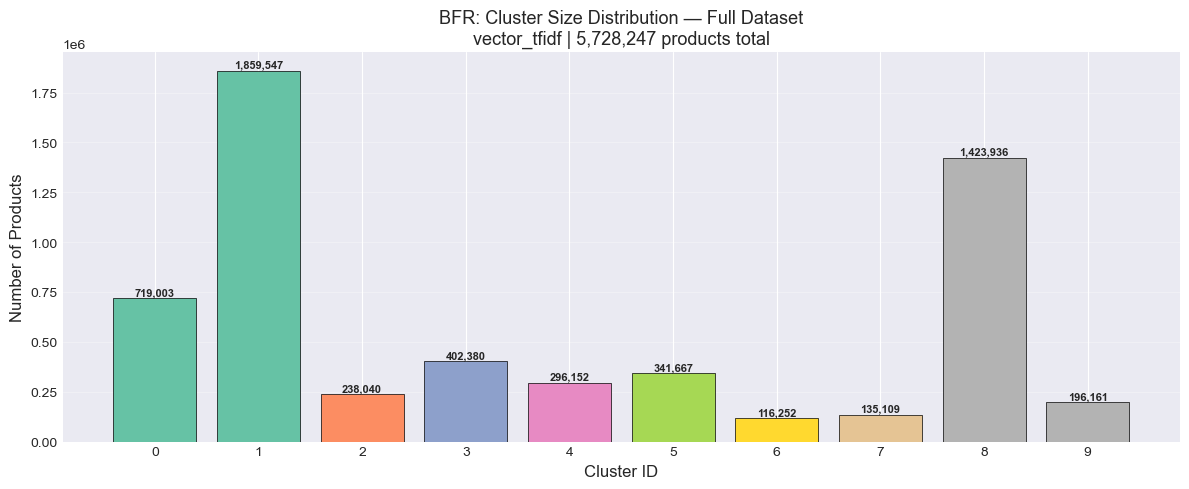

Saved: cluster_sizes_bfr_full.png


In [25]:
# Plot 1 — Cluster size bar chart (full 5.7M dataset)
fig, ax = plt.subplots(figsize=(12, 5))
colors  = cm.Set2(np.linspace(0, 1, len(full_sizes)))
bars    = ax.bar(full_sizes.index, full_sizes.values,
                 color=colors, edgecolor='black', linewidth=0.5)

for bar, val in zip(bars, full_sizes.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5000,
            f'{val:,}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xlabel('Cluster ID', fontsize=12)
ax.set_ylabel('Number of Products', fontsize=12)
ax.set_title(
    'BFR: Cluster Size Distribution — Full Dataset\n'
    f'vector_tfidf | {len(results_df):,} products total',
    fontsize=13
)
ax.set_xticks(full_sizes.index)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('cluster_sizes_bfr_full.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: cluster_sizes_bfr_full.png')


### 12b. Plot 2 : Category Composition Heatmap

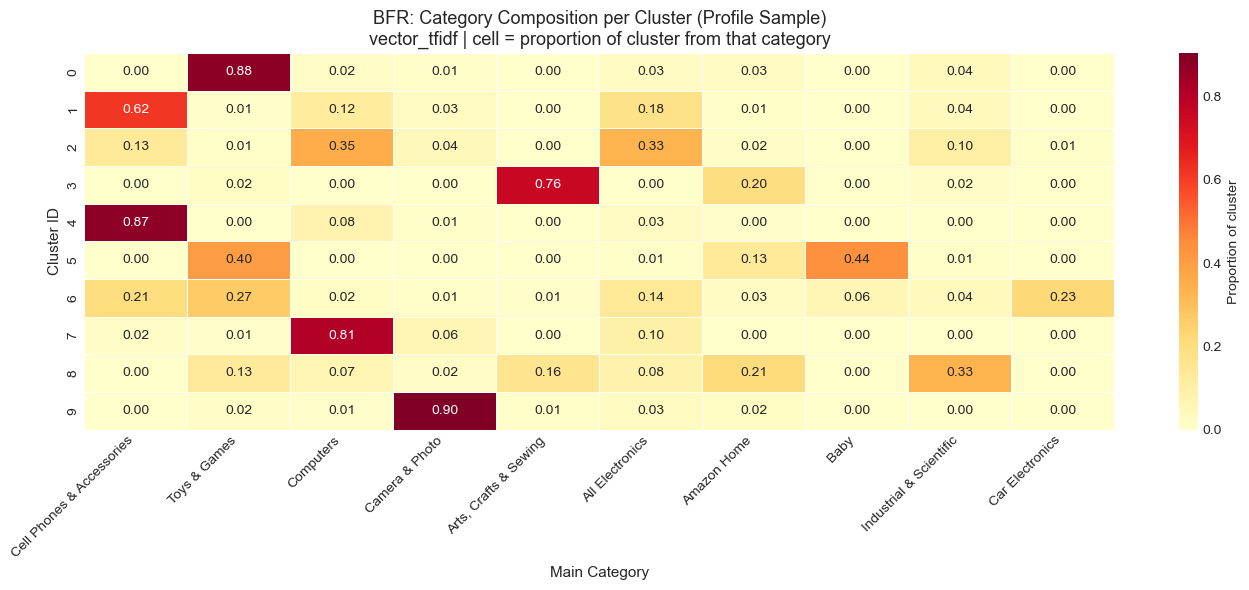

Saved: cluster_category_heatmap_bfr.png


In [26]:
# Plot 2 — Category composition heatmap (profile sample)
top_cats           = products_df['main_category'].value_counts().head(10).index.tolist()
cluster_cat_matrix = pd.crosstab(products_df['bfr_cluster'],
                                  products_df['main_category'])[top_cats]
cluster_cat_norm   = cluster_cat_matrix.div(cluster_cat_matrix.sum(axis=1), axis=0)

plt.figure(figsize=(14, 6))
sns.heatmap(cluster_cat_norm, annot=True, fmt='.2f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': 'Proportion of cluster'})
plt.title(
    'BFR: Category Composition per Cluster (Profile Sample)\n'
    'vector_tfidf | cell = proportion of cluster from that category',
    fontsize=13
)
plt.xlabel('Main Category', fontsize=11)
plt.ylabel('Cluster ID', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('cluster_category_heatmap_bfr.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: cluster_category_heatmap_bfr.png')


### 12c. Plot 3 : PCA 2D Scatter

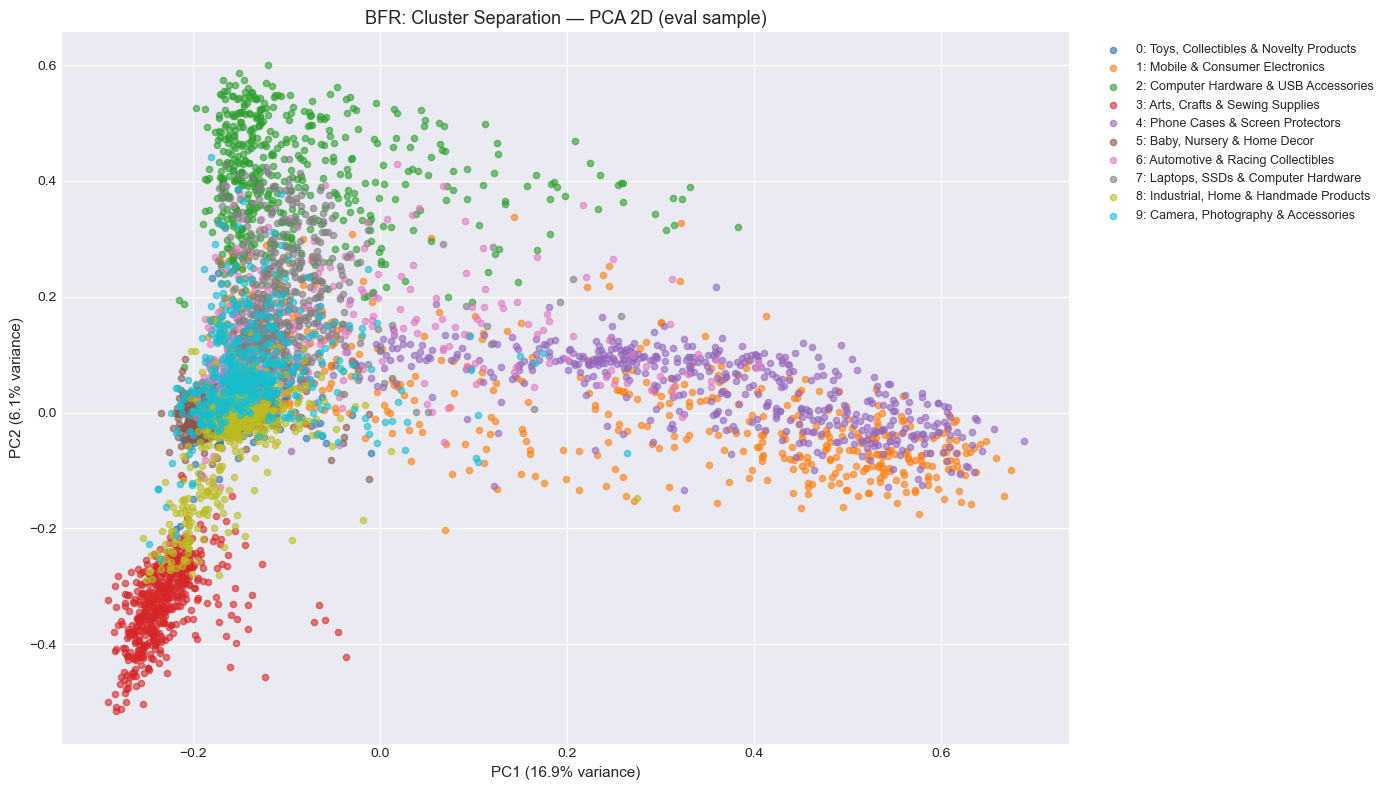

Saved: cluster_scatter_bfr.png


In [27]:
# Plot 3 — PCA 2D scatter 
pca_2d    = PCA(n_components=2, random_state=RANDOM_SEED)
X_eval_2d = pca_2d.fit_transform(X_eval)
var_exp   = pca_2d.explained_variance_ratio_

plot_df = pd.DataFrame({
    'x':       X_eval_2d[:, 0],
    'y':       X_eval_2d[:, 1],
    'cluster': eval_labels,
    'name':    [cluster_names.get(c, f'Cluster {c}') for c in eval_labels]
})

fig, ax = plt.subplots(figsize=(14, 8))
colors  = cm.tab10(np.linspace(0, 1, len(np.unique(eval_labels))))

for cid, color in zip(sorted(np.unique(eval_labels)), colors):
    mask   = plot_df['cluster'] == cid
    name   = cluster_names.get(int(cid), f'Cluster {cid}')
    sample = plot_df[mask].sample(min(500, mask.sum()), random_state=RANDOM_SEED)
    ax.scatter(sample['x'], sample['y'], c=[color],
               label=f'{int(cid)}: {name}', alpha=0.6, s=20)

ax.set_title('BFR: Cluster Separation — PCA 2D (eval sample)', fontsize=13)
ax.set_xlabel(f'PC1 ({var_exp[0]:.1%} variance)', fontsize=11)
ax.set_ylabel(f'PC2 ({var_exp[1]:.1%} variance)', fontsize=11)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.tight_layout()
plt.savefig('cluster_scatter_bfr.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: cluster_scatter_bfr.png')


## 13. Export Cluster Assignments

**`product_bfr_cluster_assignments_full.csv`** : all 5.7M `(parent_asin, bfr_cluster, bfr_cluster_name)`
**`product_bfr_cluster_assignments_profile.csv`** : ~30k profile sample with metadata for report tables


### 13a. Save Output Files

In [ ]:
#  Export 1: full cluster assignments (all 5.7M) 
full_out = results_df[['parent_asin', 'bfr_cluster', 'bfr_cluster_name']].copy()
full_out.to_csv('product_bfr_cluster_assignments_full.csv', index=False)
print(f'Saved: product_bfr_cluster_assignments_full.csv  ({len(full_out):,} rows)')

#  Export 2: profile sample with metadata 
profile_out = products_df[[
    'parent_asin', 'title', 'main_category', 'product_category',
    'price', 'average_rating', 'rating_number',
    'bfr_cluster', 'bfr_cluster_name'
]].copy()
profile_out.to_csv('product_bfr_cluster_assignments_profile.csv', index=False)
print(f'Saved: product_bfr_cluster_assignments_profile.csv  ({len(profile_out):,} rows)')

print()
print('─' * 55)
print('FINAL SUMMARY')
print('─' * 55)
print(f'Algorithm             : BFR (Bradley-Fayyad-Reina)')
print(f'Feature               : vector_tfidf (Task 2 pipeline)')
print(f'Vector dimensions     : 1,000 → {PCA_COMPONENTS} (PCA)')
print(f'Total products        : {len(full_out):,}')
print(f'Clusters              : {N_CLUSTERS}')
print(f'Silhouette (cosine)   : {silhouette:.4f}')
print(f'WCSS (sample)         : {wcss:.4f}')
print(f'Batch size            : {BATCH_SIZE:,}')
print(f'Mahal threshold       : {MAHAL_THRESHOLD}')
print(f'PCA fit sample        : {PCA_SAMPLE_SIZE:,}')
print('─' * 55)


Saved: product_bfr_cluster_assignments_full.csv  (5,728,247 rows)
Saved: product_bfr_cluster_assignments_profile.csv  (30,000 rows)

───────────────────────────────────────────────────────
FINAL SUMMARY
───────────────────────────────────────────────────────
Algorithm             : BFR (Bradley-Fayyad-Reina)
Feature               : vector_tfidf (Task 2 pipeline)
Vector dimensions     : 1,000 → 50 (PCA)
Total products        : 5,728,247
Clusters              : 10
Silhouette (cosine)   : 0.1130
WCSS (sample)         : 6103.0629
Batch size            : 10,000
Mahal threshold       : 3.0
PCA fit sample        : 50,000
───────────────────────────────────────────────────────


## 14. Report Summary Table

Load saved CSVs and print final cluster distribution for report

In [3]:
# Load saved results — no need to re-run BFR
import pandas as pd

full_df    = pd.read_csv('product_bfr_cluster_assignments_full.csv')
profile_df = pd.read_csv('product_bfr_cluster_assignments_profile.csv')

# Cluster distribution table for report
print('─' * 65)
print('CLUSTER DISTRIBUTION')
print('─' * 65)
print(f'{"Cluster Name":<45} {"Count":>10} {"Pct":>6}')
print('─' * 65)
total = len(full_df)
for name, count in full_df['bfr_cluster_name'].value_counts().sort_index().items():
    pct = count / total * 100
    print(f'{name:<45} {count:>10,} {pct:>5.1f}%')
print('─' * 65)
print(f'{"TOTAL":<45} {total:>10,} {"100.0%":>6}')
print()
print(f'Full CSV    : {len(full_df):,} products')
print(f'Profile CSV : {len(profile_df):,} products')


─────────────────────────────────────────────────────────────────
CLUSTER DISTRIBUTION
─────────────────────────────────────────────────────────────────
Cluster Name                                       Count    Pct
─────────────────────────────────────────────────────────────────
Arts, Crafts & Sewing Supplies                   402,380   7.0%
Automotive & Racing Collectibles                 116,252   2.0%
Baby, Nursery & Home Decor                       341,667   6.0%
Camera, Photography & Accessories                196,161   3.4%
Computer Hardware & USB Accessories              238,040   4.2%
Industrial, Home & Handmade Products           1,423,936  24.9%
Laptops, SSDs & Computer Hardware                135,109   2.4%
Mobile & Consumer Electronics                  1,859,547  32.5%
Phone Cases & Screen Protectors                  296,152   5.2%
Toys, Collectibles & Novelty Products            719,003  12.6%
─────────────────────────────────────────────────────────────────
TOTAL      